# Assignment 10: Spatial community composition — blobs or stripes?

### **This is an imaginary exercise.**

Maine can protect **1,000 km²** as two compact **blob** parks or two long,
narrow **stripe** parks. Each park covers 500 km². Which design would you
recommend for conserving amphibian diversity?

Follow the analyses in [Lab10](../labs/Lab10-CommunityComposition.ipynb), now
comparing park shapes. You may reuse its code and functions. Complete the code cells 
and short answers. Submit this notebook with its maps, tables, and saved summary CSVs.

## The data

[`ME_BlobStripeParks.geojson`](../data/ME_BlobStripeParks.geojson) contains two
roughly round blobs and two elliptical stripes, five times as long as they
are wide. All four are imaginary, nonoverlapping, and within Maine and the
source sample bounds. Each point already has a park assignment.

Sampling follows Lab10. All real records inside these parks are retained.
All source records in `amphibians.geojson` determine each observed species'
convex hull, its 50 km buffer, and its record-count weight. Each of **50 invented
species** inherits the buffered range and abundance weight of a randomly
sampled observed species. Added points are sampled within those ranges'
intersections with the parks, with counts proportional to the observed or
inherited weights. One point per invented species is reserved. There are
**1,500 total points**, including originals; seed = 597.

`synthetic` identifies generated points; `imaginary_species` identifies invented
taxa.

## 1. Import packages and load the data

Run from `docs/assignments` using the same environment as Lab10.

In [1]:
from pathlib import Path

import geopandas as gpd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import entropy
from scipy.spatial.distance import jaccard, braycurtis

AREA_CRS = "EPSG:5070"
COLORS = {"blob": "forestgreen", "stripe": "darkorange"}
designs = ["blob", "stripe"]

In [2]:
features = gpd.read_file("../data/ME_BlobStripeParks.geojson")
parks = features[features.feature_type == "park"].copy()
parks = parks.to_crs(AREA_CRS).set_index("park_id")
records = features[features.feature_type == "occurrence"].copy().to_crs(AREA_CRS)
park_order = list(parks.index)

display(parks[["park_name", "scenario", "area_km2"]])
print("Total occurrence records:", len(records))

,park_name,scenario,area_km2
park_id,,,
B1,Alder Crown Preserve,blob,500.0
B2,Hemlock Hollow Reserve,blob,500.0
S1,Fern Ribbon Preserve,stripe,500.0
S2,Silver Brook Reach,stripe,500.0


Total occurrence records: 1500


## 2. Map the parks and check the comparison

Map the four polygons and their points, using one color per design. Label the
park IDs. A simple map is enough.

Calculate area in km² and show the total area and number of occurrence records
for each design. Keep all records, including generated points and invented
species, in the analyses below.

scenario
blob      1000.000589
stripe    1000.000753
Name: measured_km2, dtype: float64

scenario
blob      845
stripe    655
dtype: int64

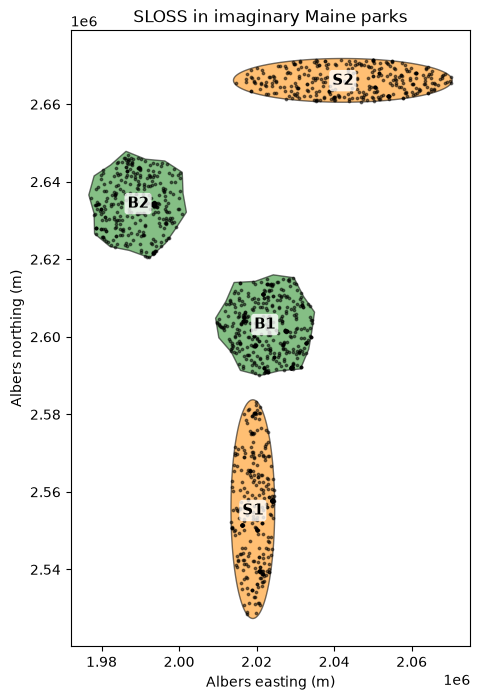

In [3]:
parks["measured_km2"] = parks.area / 1e6
display(parks.groupby("scenario").measured_km2.sum())

# Count records in each design with records.groupby("scenario").size().
display(records.groupby("scenario").size())

# Plot the parks and occurrence points; label B1, B2, S1, and S2.
fig, ax = plt.subplots(figsize=(8, 8))

for strategy, group in parks.groupby("scenario"):
    group.plot(ax=ax, color=COLORS[strategy], alpha=0.55, edgecolor="black")

records.plot(ax=ax, color="black", markersize=3, alpha=0.5)

# Annotate parks by name
for row in parks.itertuples():
    anchor = row.geometry.representative_point()
    ax.annotate(str(row.Index), (anchor.x, anchor.y),
                ha="center", va="center", fontsize=11, fontweight="bold",
                bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.8))
    ax.set(title="SLOSS in imaginary Maine parks", 
           xlabel="Albers easting (m)", 
           ylabel="Albers northing (m)")
plt.show()

**Interpretation:** What is held equal between the designs? What differs besides
shape? Predict which design will capture more species, and explain why.

*Your answer:*
All preserves have the same size area. The blob preserves are located adjacent to one another. The stripe preserves are further apart. The stripe preserves are also oriented perpendicular to each other. 
I predict that the stripe preserves will contain more species richness, because the geographical orientation allows for coverage of a greater variety of habitat types. of habitats. 

## 3. Build the community matrix

Rows are parks; columns are species; entries are record counts. A zero means
no records of that species in that park. It does not establish true absence.

In [4]:
community = pd.crosstab(records.park_id, records.species)
community = community.reindex(park_order, fill_value=0)
presence = community > 0

display(community)

species,Ambystoma laterale,Ambystoma maculatum,Anaxyrus americanus,Aquarana clamitans,Aquarana septentrionalis,Boreorana sylvatica,Desmognathus fuscus,Dryophytes versicolor,Eurycea bislineata,Fictotriton alderi,...,Sylvophantoma glacialina,Sylvophantoma hazelii,Sylvophantoma inverna,Sylvophantoma kettleii,Sylvophantoma lichenosa,Sylvophantoma mapleii,Sylvophantoma noctiluca,Sylvophantoma sprucea,Sylvophantoma willowii,Sylvophantoma zephyra
park_id,,,,,,,,,,,,,,,,,,,,,
B1,1,15,47,38,0,37,0,21,1,0,...,0,0,0,3,4,2,1,0,0,8
B2,1,17,39,21,0,26,3,11,5,0,...,0,0,1,5,5,8,0,1,1,5
S1,0,5,47,18,0,22,3,18,6,0,...,1,0,0,2,3,2,0,0,1,5
S2,1,7,11,19,1,13,0,11,4,1,...,0,1,0,3,10,5,1,1,0,8


How many species occur in the whole dataset? Choose one species and describe
its distribution among the four parks using its column in `community`.

*Your answer:* 
There are 66 different species present in the dataset (67 columns - 1 for park_id).
*Boreorana sylvatica* is present in all four preserves, but has the highest number of records in B1, nearly equal records in B2 and S1, and a much lower number of records in S2. 

## 4. Richness, Shannon diversity, and evenness

Use the lab's function below. Shannon uses `scipy.stats.entropy`; larger values
reflect more species, greater evenness, or both.

In [5]:
def diversity(community_counts):
    results = pd.DataFrame(
        index=community_counts.index,
        columns=["n_records", "richness", "shannon"],
        dtype=float,
    )
    for unit, counts in community_counts.iterrows():
        species_present = counts[counts > 0]
        results.loc[unit, "n_records"] = counts.sum()
        if len(species_present) == 0:
            continue
        results.loc[unit, "richness"] = len(species_present)
        results.loc[unit, "shannon"] = entropy(species_present)
    return results

,n_records,richness,shannon,park_name,scenario,evenness
park_id,,,,,,
B1,436.0,51.0,3.323911,Alder Crown Preserve,blob,0.544485
B2,409.0,54.0,3.516299,Hemlock Hollow Reserve,blob,0.623327
S1,328.0,49.0,3.320299,Fern Ribbon Preserve,stripe,0.564666
S2,327.0,57.0,3.711955,Silver Brook Reach,stripe,0.718136


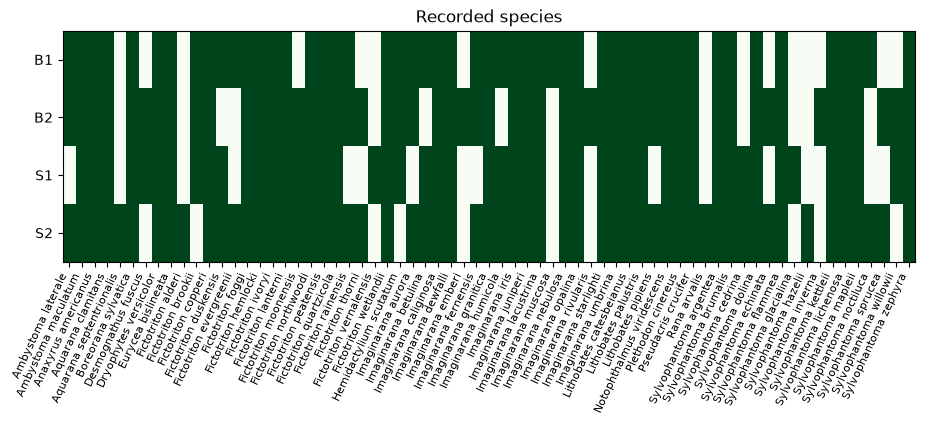

In [6]:
# Calculate park_metrics = diversity(community).
park_metrics = diversity(community)

# Add park names and scenarios from parks.
park_metrics["park_name"] = parks.park_name
park_metrics["scenario"] = parks.scenario

# Add evenness = np.exp(shannon) / richness, as in Lab10.
park_metrics["evenness"] = np.exp(park_metrics["shannon"])/park_metrics["richness"]

# Display the table and make a simple richness or Shannon plot.
display(park_metrics)

fig, ax = plt.subplots(figsize=(11, 3))
image = ax.imshow(presence.astype(int), aspect="auto", cmap="Greens", vmin=0, vmax=1)
ax.set(yticks=range(len(community)), yticklabels=community.index,
       xticks=range(len(community.columns)), xticklabels=community.columns,
       title="Recorded species")
plt.setp(ax.get_xticklabels(), rotation=65, ha="right", fontsize=8)
plt.show()

Does the richest park also have the highest Shannon diversity and evenness?
What would adding 100 records of an already common species do to these measures?

*Your answer:* Yes, S2 has the highest species richness (57), the highest Shannon diveristy value (3.71), and the highest evenness value (0.72). If 100 records of an already common species were added: it would have no effect on the species richness (that species is already present and captured within the richness value), it would decrease the Shannon diversity value, and it would decrease the evenness. (Important note: Shannon diversity is not comparable across sites with different species richness, so it is important to look at evenness for comparisons between sites.)

## 5. Alpha, beta, and gamma diversity

Pool the two blob parks, then the two stripe parks. For each design, calculate:

- **Alpha:** mean richness of its two parks.
- **Gamma:** richness in the pooled species list.
- **Multiplicative beta:** gamma divided by alpha.
- Total records and pooled Shannon diversity.

Keep the park rows in `community`; use `design_counts` for the pooled rows.

In [7]:
designs = ["blob", "stripe"]
design_counts = pd.DataFrame(
    index=designs, columns=community.columns, dtype=float)

for design in designs:
    park_ids = parks[parks.scenario == design].index
    design_counts.loc[design] = community.loc[park_ids].sum()

# Use diversity(design_counts) to start design_metrics.
design_metrics = diversity(design_counts)

# Rename its richness column to gamma_richness.
design_metrics = design_metrics.rename(columns={"richness": "gamma_richness"})

# For each design, find its two rows in park_metrics.   
# Calculate mean_park_alpha and beta_ratio, then display design_metrics.
for design in designs:
    local_parks = park_metrics[park_metrics.scenario == design]
    alpha = local_parks.richness.mean()
    gamma = design_metrics.loc[design, "gamma_richness"]
    design_metrics.loc[design, "mean_park_alpha"] = alpha
    design_metrics.loc[design, "beta_ratio"] = gamma / alpha
    design_metrics.loc[design, "sum_park_richness"] = local_parks.richness.sum()
    design_metrics.loc[design, "area_km2"] = parks[parks.scenario == design].measured_km2.sum()
display(design_metrics)

,n_records,gamma_richness,shannon,mean_park_alpha,beta_ratio,sum_park_richness,area_km2
blob,845.0,60.0,3.460793,52.5,1.142857,105.0,1000.000589
stripe,655.0,63.0,3.606102,53.0,1.188679,106.0,1000.000753


Which design has higher gamma diversity? Does alpha or complementarity between
its two parks help explain the result? Why is pooled richness generally smaller
than the sum of the two park richnesses?

List species recorded only in blobs and species recorded only in stripes.
Hint: make a `set` from the species with positive counts in each pooled row;
subtract one set from the other.

*Your answer:*
- Stripe strategy has higher gamma diversity (63, vs 60 in blob strategy) and higher Shannon diversity, even though it has fewer records than the Blob strategy. Mean park richness (Alpha) is very close between the two strategies, so that doesn't explain the difference in gamma diveristy. Pooled richness (gamma diversity) is smaller than the sum because species found in both parks will be counted twice when calculatigng species richness, but only once for gamma.

In [8]:
# Make blob_species and stripe_species from design_counts.
blob_counts = design_counts.loc["blob"]
stripe_counts = design_counts.loc["stripe"]
blob_species = set(blob_counts[blob_counts > 0].index)
stripe_species = set(stripe_counts[stripe_counts > 0].index)

# Print species unique to each design.
print("Only in the blob preserves:", sorted(blob_species - stripe_species))
print("Only in the stripe preserves:", sorted(stripe_species - blob_species))
print("In both strategies:", len(blob_species & stripe_species))

Only in the blob preserves: ['Imaginarana emberi', 'Imaginarana muscosa', 'Imaginarana rivularis', 'Sylvophantoma inverna']
Only in the stripe preserves: ['Aquarana septentrionalis', 'Fictotriton alderi', 'Fictotriton vernalensis', 'Rana arvalis', 'Sylvophantoma cedrina', 'Sylvophantoma glacialina', 'Sylvophantoma hazelii']
In both strategies: 56


### Jaccard dissimilarity

Jaccard compares presence/absence: 0 means identical species lists; 1 means no
shared species. Use `scipy.spatial.distance.jaccard` on rows of `presence`.

In [9]:
print("B1 versus B2:", jaccard(presence.loc["B1"], presence.loc["B2"]))
print("S1 versus S2:", jaccard(presence.loc["S1"], presence.loc["S2"]))

# Build jaccard_distances, a four-by-four table, as in Lab10.
# Use nested loops over park_order and jaccard(presence.loc[a], presence.loc[b]).
jaccard_distances = pd.DataFrame(index=park_order, columns=park_order, dtype=float)
for park_a in park_order:
    for park_b in park_order:
        jaccard_distances.loc[park_a, park_b] = jaccard(
            presence.loc[park_a], presence.loc[park_b]
        )

# Display the table.
display(jaccard_distances.round(2))

B1 versus B2: 0.25
S1 versus S2: 0.31746031746031744


,B1,B2,S1,S2
B1,0.00,0.25,0.25,0.20
B2,0.25,0.00,0.28,0.27
S1,0.25,0.28,0.00,0.32
S2,0.20,0.27,0.32,0.00


Compare B1–B2 with S1–S2. Which design's two parks have more different species
lists? Does that agree with the beta ratios? Explain why Jaccard alone cannot
distinguish species replacement from differences in richness.

*Your answer:* 
- When evaluating using Jaccard Dissimilarity, the two stripe preserves differ most. S1 - S2 is 0.32 vs B1 - B2 is 0.25. This means that roughly 1/3 of the species in a stripe preserve is unique compared to the other stripe preserve. And roughly 1/4 of the species found in a blob preserve is unique compared to the other blob preserve.
- Yes it agrees. The beta ratios were 1.14 for blobs and 1.19 for stripes.
- Jaccard dissimilarity is just on value and is based on the shared and union of species present int the two parks. If you have high species replacement (turnover), each park has species that the other lacks and you would have a high value. If you have a high richness difference, that could lead to a high value. These two situations can have the same/similar Jacaard Dissimilarity value, but very different ecological interpreations. 

### Bray–Curtis dissimilarity

Use `scipy.spatial.distance.braycurtis` on record counts. Make a second
four-by-four table, `bray_curtis_distances`.

Then repeat the B1–B2 and S1–S2 comparisons using **relative frequencies**:
divide each park's species counts by its total records before calling
`braycurtis`.

In [10]:
print("B1 versus B2:", braycurtis(community.loc["B1"], community.loc["B2"]))
print("S1 versus S2:", braycurtis(community.loc["S1"], community.loc["S2"]))

# Build and display bray_curtis_distances using the Jaccard loop pattern.
# For each within-design pair, divide each row by its sum and compare again.
bray_curtis_distances = pd.DataFrame(index=park_order, columns=park_order, dtype=float)
for park_a in park_order:
    for park_b in park_order:
        bray_curtis_distances.loc[park_a, park_b] = braycurtis(
            community.loc[park_a], community.loc[park_b]
        )
display(bray_curtis_distances.round(2))

B1 versus B2: 0.19763313609467456
S1 versus S2: 0.30381679389312977


,B1,B2,S1,S2
B1,0.00,0.20,0.24,0.33
B2,0.20,0.00,0.25,0.27
S1,0.24,0.25,0.00,0.30
S2,0.33,0.27,0.30,0.00


Do Jaccard and Bray–Curtis tell the same story? What information does Bray–Curtis
add? Why can unequal record totals affect its values, and what changes when
you use relative frequencies?

*Your answer:*
- Do they tell the same story: Yes, both measures indicate that the stripe pair is more dissimilar. The gap between the blob preserves and the stripe preserves is slightly larger in Bray-Curtis. However, there is a difference when we look at the individual preserve-pair comparisons. For Jacaard, blob preserves were most similar, but under Bray-Curtis, the stripes are more similar.
- Bray-Curtis accounts for differences in abundance. Jaccard is only based on whether a species is present, but B-C includes how many of that species is recorded. 
- Unequal record totals can make two parks look different even if the community is the same. If relative frequencies are used, it will normalize the values and allow for better comparison between the parks (comparing like with like). This could be important particularly if there is uneven sampling effort between the two areas.

## 6. Compare equal numbers of records

Use record-based rarefaction to check whether the pooled richness comparison
persists when both designs contribute the same number of records. Draw without
replacement and repeat **300 times**, following the lab's loop.

For each design, report mean richness and the 2.5th and 97.5th percentiles of
the draws. These percentiles describe resampling variation, not confidence
intervals for true richness. Equal record counts do not establish equal survey
effort or detectability.

In [11]:
equal_n = records.groupby("scenario").size().min()
rarefaction = pd.DataFrame()

# For each design, select its records and start an empty richness_samples list.
# Repeat 300 times:
#     sample = design_records.sample(n=equal_n, replace=False, random_state=repeat)
#     Append sample.species.nunique() to richness_samples.
# Store records_drawn, mean_richness, q025, and q975 in rarefaction.
# Use np.mean and np.quantile, then display the table.
for design in designs:
    design_records = records[records.scenario == design]
    richness_samples = []
    for repeat in range(300):
        sample = design_records.sample(n=equal_n, replace=False, random_state=repeat)
        richness_samples.append(sample.species.nunique())
    rarefaction.loc[design, "records_drawn"] = equal_n
    rarefaction.loc[design, "mean_richness"] = np.mean(richness_samples)
    rarefaction.loc[design, "q025"] = np.quantile(richness_samples, 0.025)
    rarefaction.loc[design, "q975"] = np.quantile(richness_samples, 0.975)
display(rarefaction)

,records_drawn,mean_richness,q025,q975
blob,655.0,57.423333,54.0,60.0
stripe,655.0,63.000000,63.0,63.0


Does equalizing record numbers change your preference? Which original sampling
biases and simulation assumptions remain?

*Your answer:*
- This result continues to support the stripe preserve strategy. At the same record count, we see a higher richness.
- There still may be biase in sampling effort, some species may be hard to observe/identify and that could skew the data, there might be differences in seasonality when sampling occurred, we are only comparing two design styles, habitat type might not be controlled in placement of these parks so we might actually be comparing species distribution in different habitats instead of comparing the park strategies.

## 7. Rarity and restriction within the sample

Build `species_context` with each species' total records and number of occupied
parks. Define **record-rare** as at most five records across all four parks.
Use the same four parks as the reference throughout this section.

In [12]:
species_context = pd.DataFrame()
for species in community.columns:
    counts = community[species]
    species_context.loc[species, "n_records"] = counts.sum()
    species_context.loc[species, "parks_recorded"] = sum(counts > 0)

rare_rows = species_context[species_context.n_records <= 5]
rare_species = list(rare_rows.index)
display(species_context)

,n_records,parks_recorded
Ambystoma laterale,3.0,3.0
Ambystoma maculatum,44.0,4.0
Anaxyrus americanus,144.0,4.0
Aquarana clamitans,96.0,4.0
Aquarana septentrionalis,1.0,1.0
...,...,...
Sylvophantoma mapleii,17.0,4.0
Sylvophantoma noctiluca,2.0,2.0
Sylvophantoma sprucea,2.0,2.0
Sylvophantoma willowii,2.0,2.0


Reuse `restriction_metrics` from Lab10 to calculate each park's:

- Sample-exclusive richness: species recorded in only one of the four parks.
- Weighted endemism proxy (WE): sum of `1 / parks_recorded` for species present.
- Corrected WE (CWE): WE divided by park richness.
- Record-rare richness: number of record-rare species present.

Compare the two designs' **pooled record-rare richness** as well: count each rare
species once per design, even if both parks record it.

In [13]:
# Copy the restriction_metrics function from Lab10.
# Calculate park_restriction = restriction_metrics(community).
# Display park_metrics.join(park_restriction).

def restriction_metrics(community_counts):
    occupancy = (community_counts > 0).sum(axis=0)
    results = pd.DataFrame(
        index=community_counts.index,
        columns=["sample_exclusive", "we_proxy", "cwe_proxy", "record_rare_richness"],
        dtype=float,
    )
    for unit, counts in community_counts.iterrows():
        species_here = counts[counts > 0].index
        if len(species_here) == 0:
            continue
        exclusive = 0
        rare = 0
        weighted_endemism = 0
        for species in species_here:
            occupied_units = occupancy[species]
            weighted_endemism += 1 / occupied_units
            if occupied_units == 1:
                exclusive += 1
            if species in rare_species:
                rare += 1
        results.loc[unit, "sample_exclusive"] = exclusive
        results.loc[unit, "we_proxy"] = weighted_endemism
        results.loc[unit, "cwe_proxy"] = weighted_endemism / len(species_here)
        results.loc[unit, "record_rare_richness"] = rare
    return results

park_restriction = restriction_metrics(community)
display(park_metrics.join(park_restriction))

,n_records,richness,shannon,park_name,scenario,evenness,sample_exclusive,we_proxy,cwe_proxy,record_rare_richness
park_id,,,,,,,,,,
B1,436.0,51.0,3.323911,Alder Crown Preserve,blob,0.544485,1.0,14.833333,0.290850,9.0
B2,409.0,54.0,3.516299,Hemlock Hollow Reserve,blob,0.623327,3.0,17.666667,0.327160,13.0
S1,328.0,49.0,3.320299,Fern Ribbon Preserve,stripe,0.564666,2.0,15.000000,0.306122,8.0
S2,327.0,57.0,3.711955,Silver Brook Reach,stripe,0.718136,4.0,19.500000,0.342105,17.0


In [14]:
# For each design, loop through rare_species.
# Count a species once if design_counts.loc[design, species] > 0.
design_rare = pd.DataFrame(index=designs, columns=["rare_species_captured"], dtype=float)

for design in designs:
    captured = 0
    for species in rare_species:
        if design_counts.loc[design, species] > 0:
            captured += 1
    design_rare.loc[design, "rare_species_captured"] = captured

display(design_rare)

,rare_species_captured
blob,17.0
stripe,20.0


Does a park with high WE also have high CWE? Which design captures more
record-rare species? Are any sample-exclusive species relatively well recorded?
Explain why these results do not establish that a species is endemic to a park
or has a small population. How might invented species with few generated
records affect these metrics?

*Your answer:*
- Yes, the S2 park has the highest WE (19.5) and CWE (0.34). 
- The stripe design captures more record-rare species. 
- This doesn't establish endemism because we are evaluating a very small area, we would need to evaluate a much wider geographic scale to start addressing whether a species was endemic or not. This current data reflects observed record numbers but doesn't actually quantify abundance and does not include absence data.
- The invented species with few records can skew the metrics by inflating the number of rare species present for certain parks (it will push WE and CWE up). It may also lead to patterns that are a feature of the simulated data and not patterns from the different park strategies themselves.

## 8. Save results and make a recommendation

Save `park_metrics.join(park_restriction)`, `design_metrics`, `species_context`,
`jaccard_distances`, `bray_curtis_distances`, and `rarefaction` as CSVs.

In [15]:
output_dir = Path("outputs/Assignment10")
output_dir.mkdir(parents=True, exist_ok=True)

# Save each table with .to_csv(output_dir / "table_name.csv").

park_metrics.join(park_restriction).to_csv(output_dir / "park_metrics.csv")

jaccard_distances.to_csv(output_dir / "park_jaccard.csv")
bray_curtis_distances.to_csv(output_dir / "park_bray_curtis.csv")

### Conservation recommendation (400–600 words)

Recommend blobs, stripes, or explain why the evidence does not favor one.
Support your conclusion with your map and numerical results. Address:

1. Alpha, gamma, beta, and the species contributed by each design.
2. Shannon diversity, evenness, Jaccard, and Bray–Curtis: which comparisons
   influence your decision, and why?
3. Whether rarefaction changes the result, and what rarity and restriction add.
4. Why these four locations cannot isolate a causal effect of shape. The sampler
   includes geographic ranges and reporting patterns, but no explicit edge
   effects, dispersal, or population persistence. What additional biological
   evidence or repeated park placements would help test your explanation?

*Your recommendation:*

Based on our analysis, I recommend that we proceed with using the stripe design strategy for our parks. We found that the two stripe preserves captured higher species richness compared with the blob preserves at the same conserved area. However, this difference is marginal and should be considered as a provisional evaluation. 
1. Alpha, gamma, beta, and species: The alpha metric was nearly identical for both park strategies. The gamma richness differed, with 63 species for stripe parks vs 60 for blob parks. Because the alpha diversity is nearly identical, we can determine that the gamma difference is due to complementarity. The beta ratio is 1.19 for stripes and 1.14 for blobs.
2. Shannon diversity, evenness, Jaccard and Bray-Curtis Dissimilarities: Stripe preserves Shannon diversity was higher than the blob preserves, but because this metric describes how records are spread among species and is dependent upon sampling effort, we don't want to place too much weight on this individual metric. The pair-wise park comparisons provide more informative metrics - both Jaccard and Bray-Curtis dissimilarities were higher for stripes than blobs. However, the individual park comparisons within these two metrics were different, which indicates noise in the data.
3. Rarefaction, rarity, and restriction: Normalizing the record count between the two design strategies did not remove the advantage shown by the stripe strategy. However, this analysis used 655 records per design, so it only actual varied sampling in the blob because it used all of the records available in the stripe subset. A next step in the analysis would be to reduce the re-sampling to a number lower than the number of records available for the stripe strategy and then recompare. Rarity is consistent, with stripes having more rare species than blobs. Most of this difference is coming from just one of the stripe parks, so it is hard to determine whether this is a feature of the individual park or the strategy of the two.
4. The differences found between these two strategies may be due to the geographical placement of the individual parks more than their orientation or shape. It would be informative to repeat the analysis with increased number of parks in varying placements, compare different park sizes/shapes/orientations in the same geographical placement, and evaluate compounding features like edge effects (long, skinny shapes have more edge than round blobs). Other improvements would be to include an evaluation of the habitat where these parks are being placed, comparison of seasonal sampling differences that could bias the records, and repeating the analysis with real observations over simulated data. 